<div class="alert alert-info">
<h1> Recap GLM and friends</h1>
<h4>Environmental Statistics 5</h4>
<h4>Your Names in Here!</h4>
</div>

There is no new material this week, but these homework exercises give you the chance to practice what you have
learned in the last 4 weeks.

In [2]:
# Call the necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import pingouin as pg
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


# 1. Exercise : Warp breaks - in yarn
To make a T-shirt, cotton yarn is woven. Technically, on each [loom](https://en.wikipedia.org/wiki/Loom) (German: [*Webstuhl*](https://de.wikipedia.org/wiki/Webstuhl)) there is a fixed setup of many stretched-out "warps" (*Kettfäden*), through which the "shuttle" (*Schiffchen oder Schütze*) is passed back and forth, pulling along the "weft" (*Schussfaden*). Now, the warps are stretched out under higher tension, while the weft can be made of weaker material (e.g. wool). Clearly breaking a warp is not desirable, as it renders the woven good defective.

Two wool types were tested at three warp tensions and the number of warp breaks was counted for 9 replicate looms (data `warpbreaks`).

  1. Plot the 6 resulting combinations of wool type and tension in one box plot (That is, create `interaction` variable from `wool` and `tension` and plot against `breaks`). (**2 points**)
  2. Analyse the data properly, including an interaction between `wool` type and `tension`. (Remember to check whether dispersion is acceptable and use alternative model type if required.) (**4 points**)
  3. Present and interpret the **ANOVA**-like table for this experiment (not the `summary`). `Hint:`Use `ols()` or `pingouin` for the ANOVA results.  (**2 points**)
  4. Bonus: Make a *nice* figure, grouping the boxes of the two wool types next to each other. (**3 points**)

In [3]:
# call/load dataset
warpbreaks = pd.read_csv("warpbreaks.csv")
warpbreaks.describe()

,breaks
count,54.000000
mean,28.148148
std,13.198638
min,10.000000
25%,18.250000
50%,26.000000
75%,34.000000
max,70.000000


In [4]:
warpbreaks.head(6)

,breaks,wool,tension
0,26,A,L
1,30,A,L
2,54,A,L
3,25,A,L
4,70,A,L
5,52,A,L


### 1.1 Plot

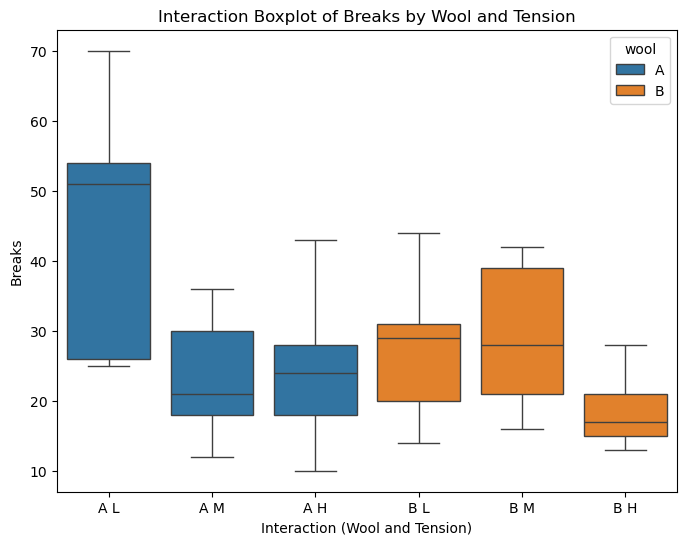

In [5]:
# Create the interaction variable
warpbreaks['interaction'] = warpbreaks['wool'] + " " + warpbreaks['tension']

# Set the style and color palette (optional)
#sns.set_style("whitegrid")
#sns.set_palette("pastel")

# Create the interaction boxplot
plt.figure(figsize=(8, 6))
sns.boxplot(x='interaction', y='breaks', data=warpbreaks, hue=warpbreaks['wool'])

# Set plot title and labels
plt.title('Interaction Boxplot of Breaks by Wool and Tension')
plt.xlabel('Interaction (Wool and Tension)')
plt.ylabel('Breaks')
plt.grid(False)

# Show the plot
plt.show()

### 1.2 Analyse

In [6]:
formula = 'breaks ~ wool * tension'

mod = sm.GLM.from_formula(formula, family=sm.families.Poisson(), data=warpbreaks).fit()

# Print the summary
print(mod.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                 breaks   No. Observations:                   54
Model:                            GLM   Df Residuals:                       48
Model Family:                 Poisson   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -228.48
Date:                Tue, 11 Nov 2025   Deviance:                       182.31
Time:                        00:09:00   Pearson chi2:                     181.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.8813
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  3

In [7]:
dispersion = mod.deviance/mod.df_resid
print('Dispersion value is : ', dispersion)

Dispersion value is :  3.798023568455141


Dispersion is too high, thus go for negative binomial.

In [8]:
''' Again we need to first estimate the what `alpha` value to use?
'''
warpbreaks2 = warpbreaks.copy()
warpbreaks2['lambda_'] = mod.mu

warpbreaks2['ols_dep'] = warpbreaks2.apply(lambda x: ((x['breaks'] - x['lambda_'])**2 - x['lambda_']) / x['lambda_'], axis=1)

ols_expr = """ols_dep ~ lambda_ - 1""" 
    
olsr_results = smf.ols(ols_expr, warpbreaks2).fit()
print(olsr_results.params)


lambda_    0.091309
dtype: float64


In [9]:
mod2 = sm.GLM.from_formula(formula, family=sm.families.NegativeBinomial(alpha=0.091309), data=warpbreaks).fit()

# Print the summary
print(mod2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 breaks   No. Observations:                   54
Model:                            GLM   Df Residuals:                       48
Model Family:        NegativeBinomial   Df Model:                            5
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -195.63
Date:                Tue, 11 Nov 2025   Deviance:                       49.949
Time:                        00:09:05   Pearson chi2:                     48.3
No. Iterations:                     4   Pseudo R-squ. (CS):             0.4367
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  3

In [10]:
dispersion = mod2.deviance/mod2.df_resid
print('Dispersion value is : ', dispersion)

Dispersion value is :  1.0405961628115417


In [11]:
rsqr = (1 - (mod2.deviance/mod2.null_deviance))*100
print('R-square is : ', rsqr)

R-square is :  38.28922144198932


**How to interpret:**<br>

1. **High Tension (Reference Level):** <br>
Wool A: The log expected count for wood A, High tension = 3.2009 <br>
Wool B: The log expected count for Wool B, High tension =3.2009−0.2683 = 2.9326 <br>

*Interpretation:* <br>
For high tension, wool B has a lower expected count of breaks than wool A. It reduces the expected count of breaks by about exp(−0.2683) ≈ 0.76 times, or 24%, compared to wool A.

2. **Low Tension:** <br>
Wool A: The log expected count for Wool A, Low tension = 3.2009+0.5958 = 3.7967 <br>
Wool B: The log expected count for Wool B, Low tension = 3.2009−0.2683+0.5958−0.1884=3.3400 <br>

*Interpretation:* <br>
At low tension, wool B again has a lower expected count of breaks compared to wool A. Wool B reduces the expected count of breaks by exp(3.3400−3.7967) ≈ 0.58 times, or about 42%, compared to wool A under low tension.

3. **Medium Tension:** <br>
Wool A: The log expected count for Wool A, Medium tension =3.2009−0.0229=3.1780 <br>
Wool B: The log expected count for Wool B, Medium tension =3.2009−0.2683−0.0229+0.4498 = 3.3595 <br>

*Interpretation:* <br>
At medium tension, wool B has a higher expected count of breaks than wool A. Here, it increases the expected count by exp(3.3595−3.1780) ≈ 1.20 times, or about 20%, compared to wool A under medium tension.

**Summary of Combined Effects:** <br>
-  High Tension: Wool B results in approximately 24% fewer breaks than wool A.
-  Low Tension: Wool B results in approximately 42% fewer breaks than wool A.
-  Medium Tension: Wool B results in approximately 20% more breaks than wool A.

By combining main and interaction effects, we get a nuanced view: wool type B consistently results in fewer breaks than wool A at high and low tension, but it increases breaks at medium tension.



In [12]:
mod3= smf.negativebinomial(formula, data=warpbreaks).fit()

# Print the summary
print(mod3.summary())

Optimization terminated successfully.
         Current function value: 3.621526
         Iterations: 6
         Function evaluations: 7
         Gradient evaluations: 7
                     NegativeBinomial Regression Results                      
Dep. Variable:                 breaks   No. Observations:                   54
Model:               NegativeBinomial   Df Residuals:                       48
Method:                           MLE   Df Model:                            5
Date:                Tue, 11 Nov 2025   Pseudo R-squ.:                 0.06222
Time:                        00:09:08   Log-Likelihood:                -195.56
converged:                       True   LL-Null:                       -208.54
Covariance Type:            nonrobust   LLR p-value:                 9.120e-05
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept        

### 1.3 ANOVA-like and interpretation

The mean number of breaks is greater than ten, thus the distribution of the response can be considered as continuous (Mize et al., 1999 and Hilbe, 2014) for ANOVA.

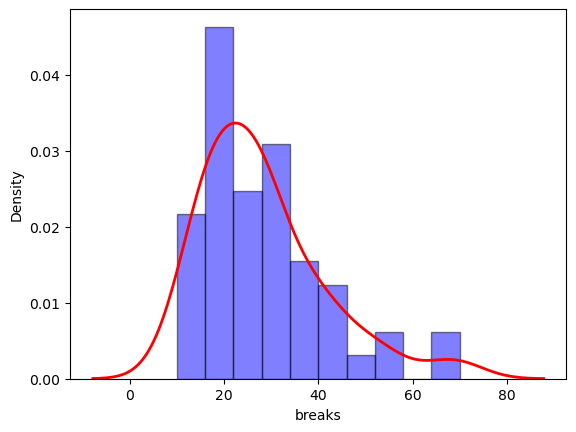

In [13]:
plt.hist(warpbreaks['breaks'], bins=10, density=True, alpha=0.5, color='blue', edgecolor='black')
sns.kdeplot(warpbreaks['breaks'], color='red', lw=2, label='Density')
plt.show()

**ANOVA Types:** <br>

1. **Type I (Sequential):** <br>
Each term is added in order, so earlier terms get credit for shared variance. <br>

2. **Type II (Hierarchical):** <br>
Tests each main effect after accounting for all other main effects, but ignoring interactions.<br>

2. **Type III (Marginal):** <br>
Tests each main effect after accounting for all other terms, including interactions.

In [14]:
mod3 = ols('breaks ~ wool * tension', data=warpbreaks).fit()

# Get the ANOVA summary
anova_results = anova_lm(mod3, typ=1) 

# Print the ANOVA summary
anova_results

,df,sum_sq,mean_sq,F,PR(>F)
wool,1.0,450.666667,450.666667,3.765288,0.058213
tension,2.0,2034.259259,1017.129630,8.498047,0.000693
wool:tension,2.0,1002.777778,501.388889,4.189069,0.021044
Residual,48.0,5745.111111,119.689815,NaN,NaN


In [15]:
mod3 = ols('breaks ~ wool * tension', data=warpbreaks).fit()

# Get the ANOVA summary
anova_results = anova_lm(mod3, typ=2) 

# Print the ANOVA summary
anova_results

,sum_sq,df,F,PR(>F)
wool,450.666667,1.0,3.765288,0.058213
tension,2034.259259,2.0,8.498047,0.000693
wool:tension,1002.777778,2.0,4.189069,0.021044
Residual,5745.111111,48.0,NaN,NaN


In [16]:
mod3 = ols('breaks ~ C(wool) * C(tension)', data=warpbreaks).fit()
anova_type3 = anova_lm(mod3, typ=3)
print(anova_type3)

                         sum_sq    df          F        PR(>F)
Intercept           5426.777778   1.0  45.340347  1.884531e-08
C(wool)              150.222222   1.0   1.255096  2.681556e-01
C(tension)          2468.518519   2.0  10.312149  1.880700e-04
C(wool):C(tension)  1002.777778   2.0   4.189069  2.104419e-02
Residual            5745.111111  48.0        NaN           NaN


In [17]:
mod3 = ols('breaks ~ wool * tension', data=warpbreaks).fit()

# Get the ANOVA summary
anova_results = anova_lm(mod3, typ=3) 

# Print the ANOVA summary
anova_results

,sum_sq,df,F,PR(>F)
Intercept,5426.777778,1.0,45.340347,1.884531e-08
wool,150.222222,1.0,1.255096,2.681556e-01
tension,2468.518519,2.0,10.312149,1.880700e-04
wool:tension,1002.777778,2.0,4.189069,2.104419e-02
Residual,5745.111111,48.0,NaN,NaN


The interaction between wool and tension is significant. The plot shows that this means that wool type “B” has fewer breaks than “A” at low and high tension, but more at medium tension.

### 1.4 Nice figure

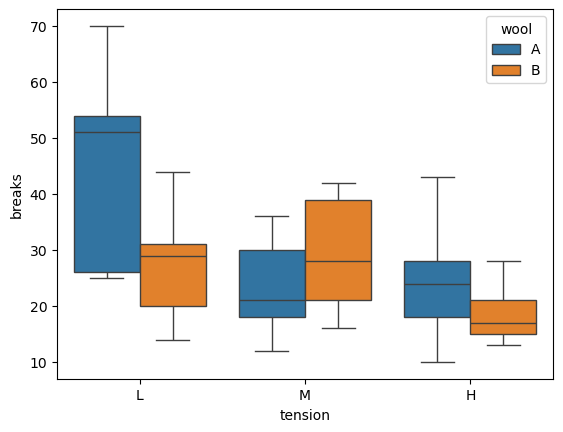

In [18]:
sns.boxplot(x=warpbreaks['tension'], y=warpbreaks['breaks'], hue=warpbreaks['wool'])
plt.grid(False)
plt.show()

## 1.5  Addendum

Note: To formally test for the difference between wool types at different tensions, we need to use post-hoc comparisons, which employ corrections for multiple testing. In this case, the only really interesting post-hoc "contrast" is between wool types at medium tension (for low and high it looks clear enough). The following code produces all pairwise comparisons, adjusted by Tukey's honest-significant-difference procedure.

Instead of a formal comparison, one could start with simply computing the expected means and their 95%-confidence interval. In this case, we already see that they substantially overlap between M A and M B, so that is all we really want to know.

In [19]:
anova2 = pg.anova(dv="breaks", between=["wool", "tension"], data=warpbreaks).round(3)
anova2

,Source,SS,DF,MS,F,p-unc,np2
0,wool,450.667,1,450.667,3.765,0.058,0.073
1,tension,2034.259,2,1017.130,8.498,0.001,0.261
2,wool * tension,1002.778,2,501.389,4.189,0.021,0.149
3,Residual,5745.111,48,119.690,NaN,NaN,NaN


In [20]:
# Perform Tukey multiple comparisons test for tension
tukey_results = pairwise_tukeyhsd(warpbreaks['breaks'], warpbreaks['tension'], alpha=0.05)

# Get the summary of the test results
print(tukey_results)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     H      L  14.7222 0.0014   5.1624  24.282   True
     H      M   4.7222 0.4631  -4.8376  14.282  False
     L      M    -10.0 0.0385 -19.5598 -0.4402   True
-----------------------------------------------------


In [21]:
# Perform Tukey multiple comparisons test for wool
tukey_results = pairwise_tukeyhsd(warpbreaks['breaks'], warpbreaks['wool'], alpha=0.05)

# Get the summary of the test results
print(tukey_results)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B  -5.7778 0.1084 -12.8752 1.3197  False
----------------------------------------------------


In [22]:
# Perform Tukey multiple comparisons test for wool at the level of each tension
results = []

for level in warpbreaks['tension'].unique():
    subset = warpbreaks[warpbreaks['tension'] == level]
    tukey_result = pairwise_tukeyhsd(subset['breaks'], subset['wool'], alpha=0.05)
    print(f"\nTukey HSD results for tension level {level}:\n", tukey_result)
    results.append(tukey_result)


Tukey HSD results for tension level L:
  Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B -16.3333 0.0302 -30.8962 -1.7704   True
-----------------------------------------------------

Tukey HSD results for tension level M:
 Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower  upper  reject
--------------------------------------------------
     A      B   4.7778 0.2795 -4.27 13.8256  False
--------------------------------------------------

Tukey HSD results for tension level H:
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B  -5.7778 0.1472 -13.8183 2.2627  False
----------------------------------------------------


In [23]:
# Perform Tukey multiple comparisons test for Tension at the level of each wool
results = []

for level in warpbreaks['wool'].unique():
    subset = warpbreaks[warpbreaks['wool'] == level]
    tukey_result = pairwise_tukeyhsd(subset['breaks'], subset['tension'], alpha=0.05)
    print(f"\nTukey HSD results for wool level {level}:\n", tukey_result)
    results.append(tukey_result)


Tukey HSD results for wool level A:
  Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     H      L     20.0  0.009   4.6801 35.3199   True
     H      M  -0.5556 0.9955 -15.8755 14.7644  False
     L      M -20.5556 0.0072 -35.8755 -5.2356   True
-----------------------------------------------------

Tukey HSD results for wool level B:
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     H      L   9.4444  0.062 -0.4069 19.2958  False
     H      M     10.0 0.0462  0.1486 19.8514   True
     L      M   0.5556 0.9891 -9.2958 10.4069  False
----------------------------------------------------


In [24]:
# Perform Tukey multiple comparisons test for wool*tension (interaction)
tukey_results = pairwise_tukeyhsd(warpbreaks['breaks'], warpbreaks['interaction'], alpha=0.05)

# Get the summary of the test results
print(tukey_results)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
   A H    A L     20.0 0.0041   4.6937  35.3063   True
   A H    A M  -0.5556    1.0 -15.8619  14.7508  False
   A H    B H  -5.7778 0.8706 -21.0841   9.5285  False
   A H    B L   3.6667 0.9797 -11.6397   18.973  False
   A H    B M   4.2222 0.9627 -11.0841  19.5285  False
   A L    A M -20.5556  0.003 -35.8619  -5.2492   True
   A L    B H -25.7778 0.0001 -41.0841 -10.4715   True
   A L    B L -16.3333 0.0302 -31.6397   -1.027   True
   A L    B M -15.7778 0.0398 -31.0841  -0.4715   True
   A M    B H  -5.2222 0.9115 -20.5285  10.0841  False
   A M    B L   4.2222 0.9627 -11.0841  19.5285  False
   A M    B M   4.7778 0.9377 -10.5285  20.0841  False
   B H    B L   9.4444 0.4561  -5.8619  24.7508  False
   B H    B M     10.0 0.3919  -5.3063  25.3063  False
   B L    B M   0.5556    1.0 -14.7508  15.8619  False
----------

From this comparison we learn that really only wool A at low tension suffers from a significantly higher number of
warp breaks than all other combinations (apart from B on medium). Also note that this model explains little deviance
(only 33 out of 87 units, see section 2.2), so we already there got an inkling that we will not find many differences.

In [25]:
# for wool
wool = pg.pairwise_tukey(dv="breaks", between="wool", data=warpbreaks).round(3)
wool

,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,A,B,31.037,25.259,5.778,3.537,1.634,0.108,0.438


In [26]:
# for tension
tension = pg.pairwise_tukey(dv="breaks", between="tension", data=warpbreaks).round(3)
tension

,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,H,L,21.667,36.389,-14.722,3.96,-3.718,0.001,-1.104
1,H,M,21.667,26.389,-4.722,3.96,-1.192,0.463,-0.528
2,L,M,36.389,26.389,10.000,3.96,2.525,0.038,0.735


In [27]:
# for interaction
interaction = pg.pairwise_tukey(dv="breaks", between="interaction", data=warpbreaks).round(3)
interaction

,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,A H,A L,24.556,44.556,-20.000,5.157,-3.878,0.004,-1.294
1,A H,A M,24.556,24.000,0.556,5.157,0.108,1.000,0.056
2,A H,B H,24.556,18.778,5.778,5.157,1.120,0.871,0.684
3,A H,B L,24.556,28.222,-3.667,5.157,-0.711,0.980,-0.347
4,A H,B M,24.556,28.778,-4.222,5.157,-0.819,0.963,-0.408
5,A L,A M,44.556,24.000,20.556,5.157,3.986,0.003,1.380
6,A L,B H,44.556,18.778,25.778,5.157,4.998,0.000,1.852
7,A L,B L,44.556,28.222,16.333,5.157,3.167,0.030,1.067
8,A L,B M,44.556,28.778,15.778,5.157,3.059,0.040,1.041
9,A M,B H,24.000,18.778,5.222,5.157,1.013,0.911,0.707


In [31]:
# scikit posthoc
import scikit_posthocs as sp
sp.posthoc_tukey(warpbreaks, val_col='breaks', group_col='interaction')

,A L,A M,A H,B L,B M,B H
A L,1.000000,0.002958,0.004095,0.030214,0.039817,0.000114
A M,0.002958,1.000000,0.999998,0.962654,0.937721,0.911478
A H,0.004095,0.999998,1.000000,0.979712,0.962654,0.870557
B L,0.030214,0.962654,0.979712,1.000000,0.999998,0.456095
B M,0.039817,0.937721,0.962654,0.999998,1.000000,0.391877
B H,0.000114,0.911478,0.870557,0.456095,0.391877,1.000000


In [33]:
sp.posthoc_tukey(warpbreaks, val_col='breaks', group_col='tension')

,L,M,H
L,1.000000,0.038460,0.001432
M,0.038460,1.000000,0.463083
H,0.001432,0.463083,1.000000


In [35]:
sp.posthoc_tukey(warpbreaks, val_col='breaks', group_col='wool')

,A,B
A,1.000000,0.108397
B,0.108397,1.000000
